<a href="https://colab.research.google.com/github/bauhaushm/TP-Delito_en_AMBA/blob/SantiagoPeralta/TP_Delito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico Grupal - Laboratorio de Métodos Cuantitativos
**Universidad de Buenos Aires - Facultad de Ciencias Económicas**  
**Tecnicatura Universitaria en Gestión y Análisis de Datos**  
**Segundo Cuatrimestre 2026**

---

### Integrantes del Grupo:
* **Chietino Luna, Micaela** - Registro: 921785 - Usuario GitHub: `@mchietino`
* **Iandoli, Franco** - Registro: 921507 - Usuario GitHub: `@Franco-Iandoli`
* **Ortiz, Naiara** - Registro: 921844 - Usuario GitHub: `@naiaraortizrodriguez`
* **Peralta, Santiago** - Registro: 921431 - Usuario GitHub: `@SantiagoNPeralta`
* **Turrillo, Bruno** - Registro: 921414 - Usuario GitHub: `@bauhaushm`

---

## 1. Introducción y Pregunta de Investigación

Nuestro grupo se focalizará en la temática del delito y su relación con aspectos sociales que pueden influir en él.

**Pregunta de investigación:**
> *¿Cómo se articulan la frecuencia y el tipo de hecho delictivo con la estructura socioeconómica y comercial de CABA y del Conurbano bonaerense?*

Incialmente usamos como fuente principal el Sistema Nacional de Información Criminal (Snic). El URL https://www.argentina.gob.ar/seguridad/estadisticascriminales/bases-de-datos contiene diferentes datasets del cual elegimos "SNIC - Departamentos. Anual. Años 2000-2025".

In [2]:
#importamos las librerías que vamos a utilizar
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas
import colorsys #para definir los colores de las barras (convierte colores de HLS a RGB)

Le pedimos a Pandas que nos haga un filtrado de filas y columnas del dataset. Acotamos el rango a la franja de años 2017-2025 (últimos 9 años) y reducimos la información a las columnas: "Año", "Provincia", "Departamentos", "Tipo de delito", "Cantidad de Hechos" y "Tasa de delito (cada 100.000 habitantes)". Nombramos al nuevo dataset obtenido.

In [3]:
# 1. Cargar únicamente las columnas A, C, E, G, H, M (índices 0, 2, 4, 6, 7, 12)
columnas = [0, 2, 4, 6, 7, 12]
url = "https://cloud-snic.minseg.gob.ar/Bases/SNIC/snic-departamentos-anual.xlsx"

df = pd.read_excel(url, usecols=columnas)
# 2. Filtrar únicamente para los años entre 2017 y 2025
df_delito = df[(df['anio'] >= 2017) & (df['anio'] <= 2025)]

# 3. Verificar el resultado
print(f"El dataset filtrado contiene {len(df_delito)} filas y {len(df_delito.columns)} columnas.")
print("Años incluidos:", sorted(df_delito['anio'].unique()))

# 4. Guardar el nuevo dataset resultante
df_delito.to_excel('snic_2017_2025_delito.xlsx', index=False)
df_delito.to_csv('snic_2017_2025_delito.csv', index=False)

El dataset filtrado contiene 288832 filas y 6 columnas.
Años incluidos: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


Visualizamos el nuevo dataframe generado

In [4]:
df_delito

,anio,provincia_nombre,departamento_nombre,codigo_delito_snic_nombre,cantidad_hechos,tasa_hechos
8448,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Homicidios dolosos,25,9.870850
8449,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Abusos sexuales con acceso carnal (violaciones),14,5.527676
8450,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Otros delitos contra la integridad sexual,190,75.018458
8451,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Delitos contra el estado civil,0,0.000000
8452,2017,Ciudad Autónoma de Buenos Aires,Comuna 1,Amenazas,1074,424.051707
...,...,...,...,...,...,...
569875,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones dolosas,341,433.627081
569876,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas en Accidentes Viales,70,89.014357
569877,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Lesiones culposas por otros hechos,1,1.271634
569878,2025,"Tierra del Fuego, Antártida e Islas del Atlánt...",Ushuaia,Otros delitos contra las personas,879,1117.765994


Contamos el total general de valores nulos (NaN) de todo el dataset:

In [5]:
df_delito.isna().sum()

,0
anio,0
provincia_nombre,0
departamento_nombre,122
codigo_delito_snic_nombre,0
cantidad_hechos,0
tasa_hechos,12805


Antes de modificar los datos nulos (Nan), evaluamos la magnitud del problema verificando la cantidad por columna y la proporción en relación al total de datos de esa columna

In [6]:
# Cantidad de nulos por columna
df_delito.isnull().sum()

# Porcentaje de nulos por columna
(df_delito.isnull().sum() / len(df)) * 100

,0
anio,0.000000
provincia_nombre,0.000000
departamento_nombre,0.021408
codigo_delito_snic_nombre,0.000000
cantidad_hechos,0.000000
tasa_hechos,2.246964


Se detectó un 0,02% de valores nulos en departamento_nombre, correspondientes a hechos reportados sin ubicación subprovincial específica, los cuales fueron imputados bajo la etiqueta 'Departamento sin determinar' para conservar la totalidad de los delitos registrados. Asimismo, el 2,25% de nulos en tasa_hechos se mantuvo sin imputar debido a la imposibilidad metodológica de calcular tasas poblacionales en geografías no delimitadas, asegurando no sesgar los cálculos de tendencia con ceros ficticios.

In [7]:
# Imputar los valores nulos en departamento_nombre
df_delito['departamento_nombre'] = df_delito['departamento_nombre'].fillna('Departamento sin determinar')

/tmp/ipykernel_4511/3213698395.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_delito['departamento_nombre'] = df_delito['departamento_nombre'].fillna('Departamento sin determinar')


In [8]:
# Verificamos que se aplicó correctamente
(df_delito.isnull().sum() / len(df_delito)) * 100

,0
anio,0.000000
provincia_nombre,0.000000
departamento_nombre,0.000000
codigo_delito_snic_nombre,0.000000
cantidad_hechos,0.000000
tasa_hechos,4.433373


In [9]:
# Para tener un pantallazo general de la evolución del delito en el area estudiada agrupamos por año la cantidad de hechos

# Agrupar por año y sumar la cantidad total de delitos por cada uno
df_delito_por_anio = df_delito.groupby('anio', as_index=False)['cantidad_hechos'].sum()

# Mostrar el nuevo dataset resultante
df_delito_por_anio

,anio,cantidad_hechos
0,2017,1669574
1,2018,1750484
2,2019,1937973
3,2020,1655061
4,2021,1772063
5,2022,1838614
6,2023,2000875
7,2024,2069909
8,2025,1954024


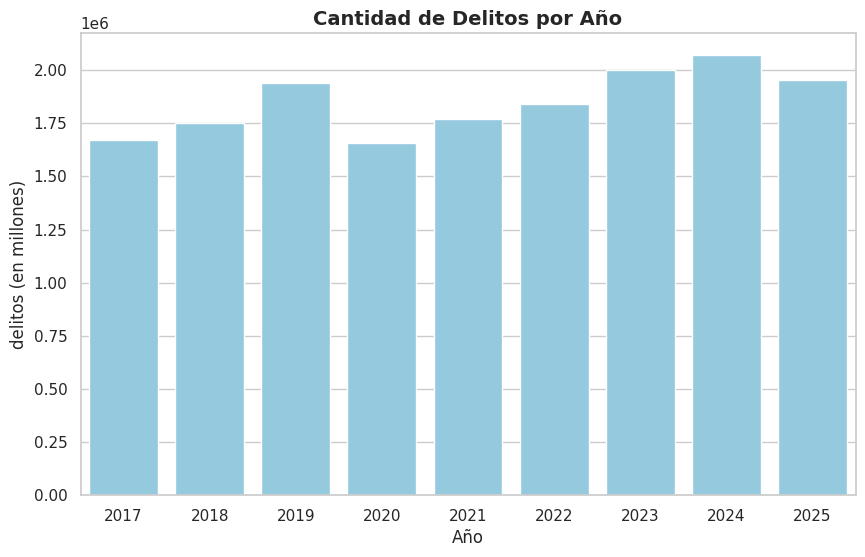

In [10]:
# Graficamos

# Configurar el estilo del gráfico
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Crear el gráfico de barras verticales
ax = sb.barplot(
    data=df_delito_por_anio,
    x='anio',
    y='cantidad_hechos',
    color='skyblue'
)

# Configurar títulos y etiquetas de los ejes
plt.title('Cantidad de Delitos por Año', fontsize=14, fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('delitos (en millones)', fontsize=12)  # Eje Y nombrado como "delitos"

# Mostrar el gráfico
plt.show()

### Gráfico de variación de la tasa de delitos, 2017-2025

Para comparar cómo cambió la tasa de delitos en cada partido del Conurbano y en cada comuna de CABA,
se calcula la variación porcentual entre 2017 y 2025 y se representa con un gráfico de barras ordenado
de menor a mayor.

**Uso del color.** Las barras se colorean en rojo si la tasa aumentó y en verde si disminuyó, de modo que
el sentido del cambio se lea de un vistazo. Además, el tono se hace más oscuro cuanto mayor es la
variación dentro de cada grupo. Para lograrlo se utiliza el módulo `colorsys` de la biblioteca estándar
de Python, que permite definir un color por su tono, su claridad y su saturación (HLS) y convertirlo a
RGB, el formato que usa matplotlib. De este modo se mantiene fija la saturación y el tono (rojo o verde) y
solo se varía la claridad, lo que produce un degradado uniforme sin que el color se vuelva grisáceo.
Esta opción no requiere instalar ninguna librería adicional.

**Cómo leer el gráfico.** La intensidad del color refleja la posición de cada barra dentro de su grupo
(rojo o verde), no su magnitud, que se lee en las etiquetas con el porcentaje.

**Aclaraciones sobre la tasa de delitos**

- Los datos corresponden a delitos denunciados y registrados (SNIC), no a la totalidad de los delitos
  ocurridos. Los hechos que no se denuncian no están incluidos y la proporción puede variar según la zona.
- La tasa se calcula cada 100.000 habitantes residentes. No considera a las personas que trabajan, estudian
  o circulan en cada lugar sin vivir en él (población flotante), por lo que en zonas de mucho tránsito
  comercial o laboral, como la Comuna 1 o Morón, la tasa puede resultar más alta de lo que sugiere el
  riesgo para los residentes.

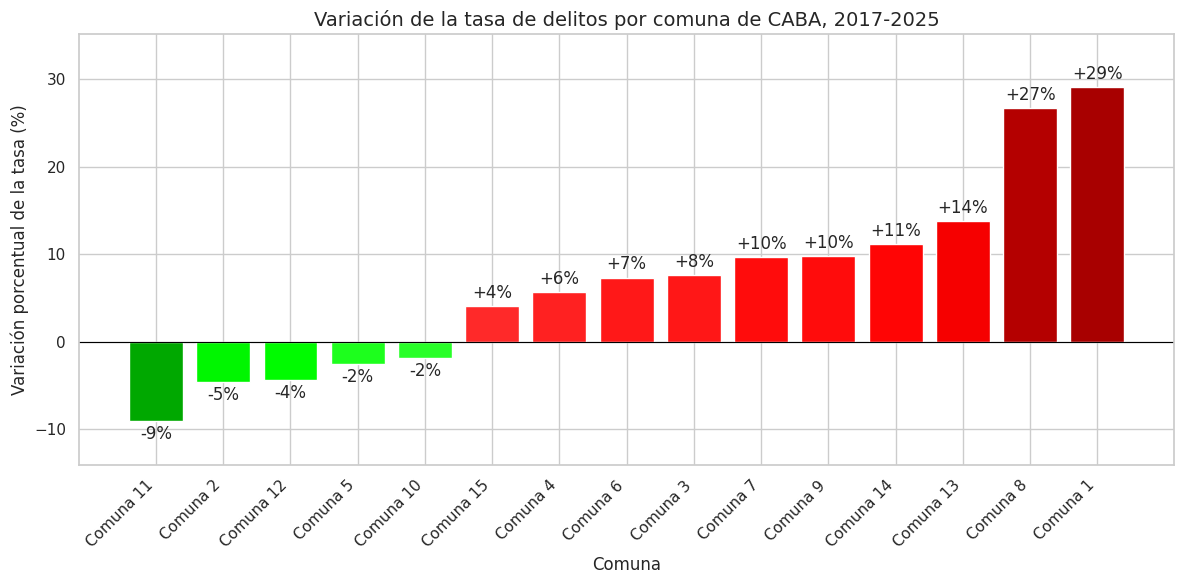

In [11]:
# 1) Filtrar CABA y excluir los hechos sin comuna determinada (no tienen tasa)
base_caba = df_delito[
    (df_delito["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires") &
    (df_delito["departamento_nombre"] != "Departamento sin determinar")
]

# 2) Tasa total por comuna y año (se suman las tasas de todos los tipos de delito)
tasa_comuna_anio = (
    base_caba
    .groupby(["anio", "departamento_nombre"], as_index=False)["tasa_hechos"]
    .sum()
)

# 3) Tabla con una fila por comuna y una columna por año
tabla = tasa_comuna_anio.pivot(index="departamento_nombre", columns="anio", values="tasa_hechos")

# 4) Variación porcentual 2017-2025, ordenada de menor a mayor (escalera)
variacion = ((tabla[2025] / tabla[2017] - 1) * 100).sort_values()

# 5) Color: rojo si subió, verde si bajó. Cuanto mayor la variación, más oscuro el tono
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    # 0 = la variación más chica de su lado (tono claro), 1 = la más grande (tono oscuro)
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)   # saturación al 100%

pos = variacion[variacion > 0].abs()    # comunas donde subió
neg = variacion[variacion < 0].abs()    # comunas donde bajó

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0       # tono 0.0 = rojo
    else color(v, 1/3, neg.min(), neg.max())           # tono 1/3 = verde
    for v in variacion
]

# 6) Gráfico
plt.figure(figsize=(12, 6))
barras = plt.bar(variacion.index, variacion.values, color=colores)
plt.bar_label(barras, labels=[f"{v:+.0f}%" for v in variacion], padding=3)   # valor en cada barra

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Variación de la tasa de delitos por comuna de CABA, 2017-2025", fontsize=14)
plt.xlabel("Comuna")
plt.ylabel("Variación porcentual de la tasa (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(variacion.min() - 5, variacion.max() + 6)    # espacio para las etiquetas
plt.tight_layout()
plt.savefig("variacion_caba_escalera.png", dpi=110)    # para incluirlo en el informe
plt.show()

### Distribución de los barrios por comuna de CABA

La Ciudad Autónoma de Buenos Aires está dividida en 15 comunas que agrupan sus 48 barrios. Para facilitar la interpretación del gráfico, se detalla qué barrios corresponden a cada comuna.

- **Comuna 1:** Retiro, San Nicolás, Puerto Madero, San Telmo, Montserrat y Constitución.
- **Comuna 2:** Recoleta.
- **Comuna 3:** Balvanera y San Cristóbal.
- **Comuna 4:** La Boca, Barracas, Parque Patricios y Nueva Pompeya.
- **Comuna 5:** Almagro y Boedo.
- **Comuna 6:** Caballito.
- **Comuna 7:** Flores y Parque Chacabuco.
- **Comuna 8:** Villa Soldati, Villa Riachuelo y Villa Lugano.
- **Comuna 9:** Liniers, Mataderos y Parque Avellaneda.
- **Comuna 10:** Villa Real, Monte Castro, Versalles, Floresta, Vélez Sarsfield y Villa Luro.
- **Comuna 11:** Villa General Mitre, Villa Devoto, Villa del Parque y Villa Santa Rita.
- **Comuna 12:** Coghlan, Saavedra, Villa Urquiza y Villa Pueyrredón.
- **Comuna 13:** Núñez, Belgrano y Colegiales.
- **Comuna 14:** Palermo.
- **Comuna 15:** Chacarita, Villa Crespo, La Paternal, Villa Ortúzar, Agronomía y Parque Chas.

Esta distribución permite identificar las zonas representadas en el gráfico y comparar la evolución de los hechos delictivos entre las distintas comunas durante el período 2017-2025.

Para analizar el Conurbano bonaerense se utiliza el listado de los 24 partidos de la provincia de
Buenos Aires que rodean a la Ciudad Autónoma de Buenos Aires. El dataset del SNIC no incluye esta
clasificación, por lo que se filtra por nombre de departamento.

In [12]:
# Los 24 partidos del Conurbano bonaerense
# (el dataset del SNIC no indica cuáles son del Conurbano; esta lista la definimos nosotros)
partidos_conurbano = [
    "Almirante Brown", "Avellaneda", "Berazategui", "Esteban Echeverría",
    "Ezeiza", "Florencio Varela", "General San Martín", "Hurlingham",
    "Ituzaingó", "José C. Paz", "La Matanza", "Lanús", "Lomas de Zamora",
    "Malvinas Argentinas", "Merlo", "Moreno", "Morón", "Quilmes",
    "San Fernando", "San Isidro", "San Miguel", "Tigre",
    "Tres de Febrero", "Vicente López",
]

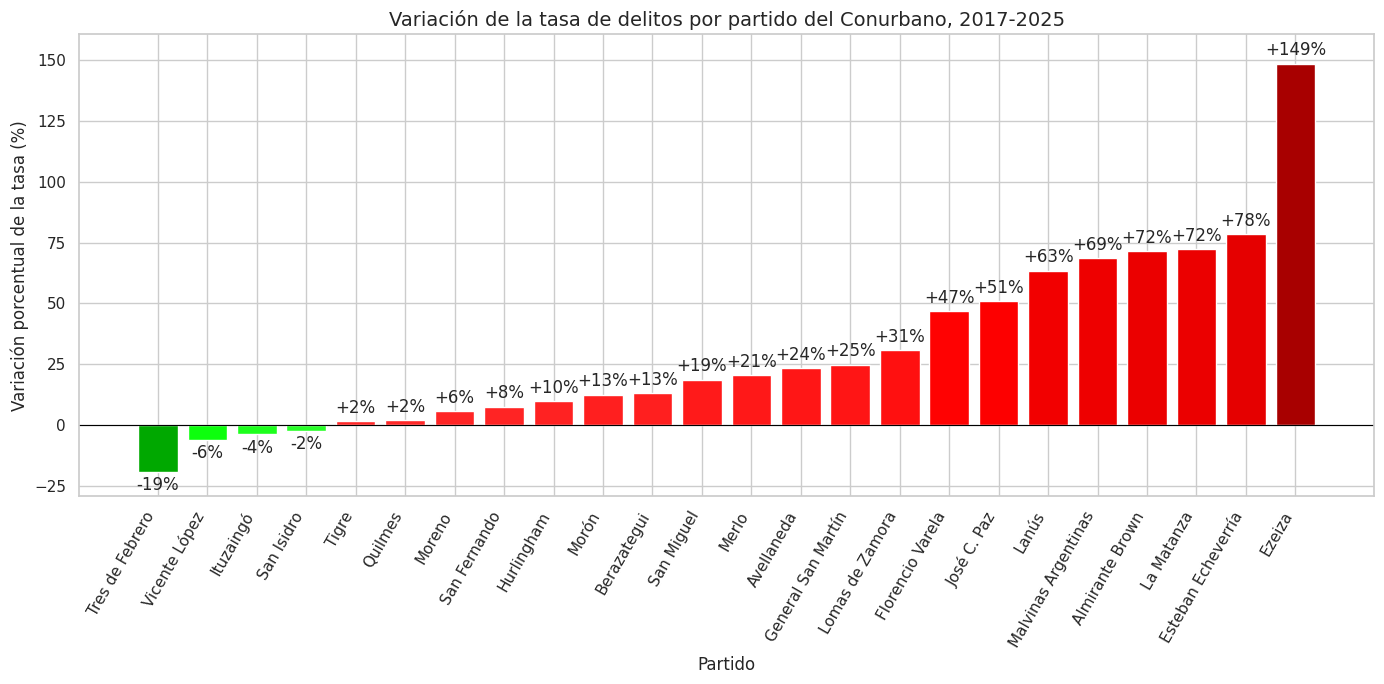

In [13]:
# 1) Filtrar provincia de Buenos Aires y los 24 partidos de la lista
base = df_delito[
    (df_delito["provincia_nombre"] == "Buenos Aires") &
    (df_delito["departamento_nombre"].isin(partidos_conurbano))
]

# 2) Tasa total por partido y año (se suman las tasas de todos los tipos de delito)
tasa_partido_anio = (
    base
    .groupby(["anio", "departamento_nombre"], as_index=False)["tasa_hechos"]
    .sum()
)

# 3) Tabla con una fila por partido y una columna por año
tabla = tasa_partido_anio.pivot(index="departamento_nombre", columns="anio", values="tasa_hechos")

# 4) Variación porcentual 2017-2025, ordenada de menor a mayor (escalera)
variacion = ((tabla[2025] / tabla[2017] - 1) * 100).sort_values()

# 5) Color: rojo si subió, verde si bajó. Cuanto mayor la variación, más oscuro el tono
def color(v, tono, v_min, v_max, l_claro=0.58, l_oscuro=0.33):
    t = 0 if v_max == v_min else (abs(v) - v_min) / (v_max - v_min)
    return colorsys.hls_to_rgb(tono, l_claro - t * (l_claro - l_oscuro), 1.0)

pos = variacion[variacion > 0].abs()
neg = variacion[variacion < 0].abs()

colores = [
    color(v, 0.0, pos.min(), pos.max()) if v > 0       # rojo
    else color(v, 1/3, neg.min(), neg.max())           # verde
    for v in variacion
]

# 6) Gráfico
plt.figure(figsize=(14, 7))
barras = plt.bar(variacion.index, variacion.values, color=colores)
plt.bar_label(barras, labels=[f"{v:+.0f}%" for v in variacion], padding=3)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Variación de la tasa de delitos por partido del Conurbano, 2017-2025", fontsize=14)
plt.xlabel("Partido")
plt.ylabel("Variación porcentual de la tasa (%)")
plt.xticks(rotation=60, ha="right")
plt.ylim(variacion.min() - 10, variacion.max() + 12)
plt.tight_layout()
plt.savefig("variacion_conurbano_escalera.png", dpi=110)
plt.show()

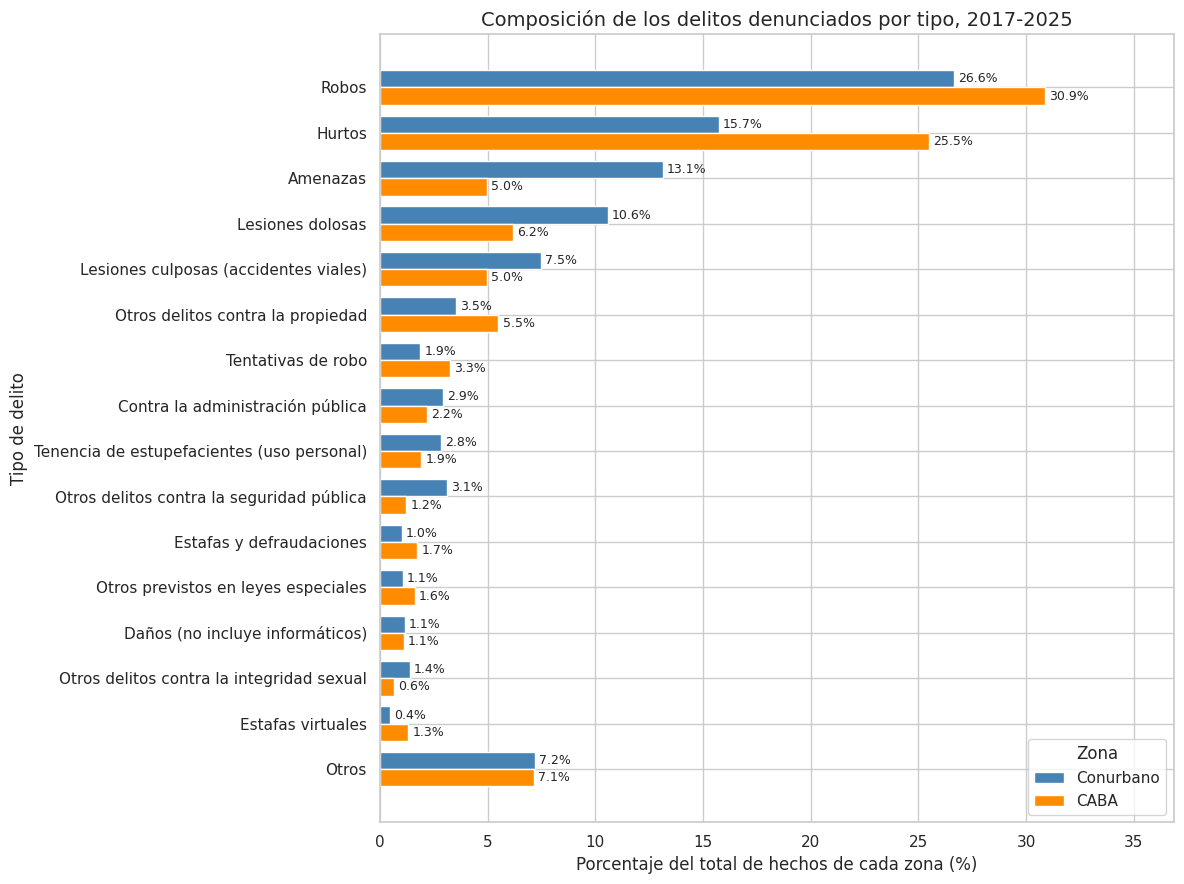

In [14]:
# 1) Conurbano y CABA, cada uno con su etiqueta de zona
conu = df_delito[
    (df_delito["provincia_nombre"] == "Buenos Aires") &
    (df_delito["departamento_nombre"].isin(partidos_conurbano))
].assign(zona="Conurbano")

caba = df_delito[
    (df_delito["provincia_nombre"] == "Ciudad Autónoma de Buenos Aires") &
    (df_delito["departamento_nombre"] != "Departamento sin determinar")
].assign(zona="CABA")

base = pd.concat([conu, caba])

# 2) Nombres más cortos para que entren en el gráfico (el resto queda con su nombre original)
nombres_cortos = {
    "Robos (excluye los agravados por el resultado de lesiones y/o muertes)": "Robos",
    "Lesiones culposas en Accidentes Viales": "Lesiones culposas (accidentes viales)",
    "Tentativas de robo (excluye las agravadas por el res. de lesiones y/o muerte)": "Tentativas de robo",
    "Delitos contra la administración pública": "Contra la administración pública",
    "Estafas y defraudaciones (no incluye virtuales) y usura": "Estafas y defraudaciones",
    "Estafas y defraudaciones asistidas virtualmente": "Estafas virtuales",
    "Tenencia simple atenuada para uso personal de estupefacientes": "Tenencia de estupefacientes (uso personal)",
    "Otros delitos previstos en leyes especiales": "Otros previstos en leyes especiales",
}
base["tipo"] = base["codigo_delito_snic_nombre"].map(nombres_cortos).fillna(base["codigo_delito_snic_nombre"])

# 3) Hechos por zona y tipo, y porcentaje sobre el total de cada zona
hechos = base.groupby(["zona", "tipo"])["cantidad_hechos"].sum().unstack(0).fillna(0)
pct = hechos / hechos.sum() * 100

# 4) Los N tipos más frecuentes de CADA zona (se unen, sin repetir)
N = 12
top = sorted(
    set(pct["Conurbano"].nlargest(N).index) | set(pct["CABA"].nlargest(N).index),
    key=lambda t: pct.loc[t].sum(),
    reverse=True
)

tabla = pct.loc[top]
tabla.loc["Otros"] = 100 - tabla.sum()     # agrupación propia con todo lo demás
tabla = tabla.iloc[::-1]                    # el más frecuente queda arriba

# 5) Gráfico de barras agrupadas
y = np.arange(len(tabla))
h = 0.38
fig, ax = plt.subplots(figsize=(12, 9))
b1 = ax.barh(y + h/2, tabla["Conurbano"], h, label="Conurbano", color="steelblue")
b2 = ax.barh(y - h/2, tabla["CABA"], h, label="CABA", color="darkorange")
ax.bar_label(b1, fmt="%.1f%%", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(tabla.index)
ax.set_title("Composición de los delitos denunciados por tipo, 2017-2025", fontsize=14)
ax.set_xlabel("Porcentaje del total de hechos de cada zona (%)")
ax.set_ylabel("Tipo de delito")
ax.set_xlim(0, tabla.max().max() + 6)
ax.legend(title="Zona")
plt.tight_layout()
plt.savefig("tipos_delito.png", dpi=110)
plt.show()